Before starting, upload the .SAFE.zip file of the before and after image of the given district on your Google Drive.
Also download Sentinel Toolboxes for Linux 64-bit (Main Download) from this link : -https://step.esa.int/main/download/snap-download/, and upload the downloaded .sh file on your google drive as well.
If at any point you ran out of RAM, go to runtime and click Restart session. We are saving our output after every step so it wont affect the execution of further cells. Some cells(usually for saving the output on disc) might take around 30 minutes to execute.

INSTALLING DEPENDENCIES

In [3]:
# ============================================================
# 1. Check Python and Java versions
# ============================================================
!python --version
import sys
print(sys.version)
!java -version

# ============================================================
# 2. Install Linux dependencies
# ============================================================
!apt-get update -qq
!apt-get install -y -qq wget unzip curl
!which java

# ============================================================
# 3. Mount Drive, COPY installer to local disk, make executable
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

DRIVE_INSTALLER = "/content/drive/MyDrive/esa-snap_sentinel_linux-14.0.0.sh"
LOCAL_INSTALLER = "/content/esa-snap_sentinel_linux-14.0.0.sh"

!cp "{DRIVE_INSTALLER}" "{LOCAL_INSTALLER}"
!chmod +x "{LOCAL_INSTALLER}"
!ls -lh "{LOCAL_INSTALLER}"
!file "{LOCAL_INSTALLER}"

# ============================================================
# 4. Run the installer locally (only once)
# ============================================================
!rm -rf /opt/snap
!mkdir -p /opt/snap
!bash "{LOCAL_INSTALLER}" -q -dir /opt/snap

# ============================================================
# 5. Check that SNAP actually installed
# ============================================================
!find /opt/snap -maxdepth 2 -type f | head -50
!ls -lah /opt/snap
!/opt/snap/bin/gpt -h

# ============================================================
# 6. Check that Sentinel-1 operators exist
# ============================================================
!/opt/snap/bin/gpt -h Apply-Orbit-File

# ============================================================
# 7. Configure esa_snappy (Python <-> SNAP bridge)
# ============================================================
import sys
print(sys.executable)

!/usr/bin/python3 -m pip install esa-snappy
!find /opt/snap -iname "*snappy-conf*" -o -iname "*snappyutil*"
!/opt/snap/bin/snappy-conf /usr/bin/python3

# ============================================================
# 8. Test Python <-> SNAP integration
# ============================================================
!/usr/bin/python3 -c "import esa_snappy; print(esa_snappy.__file__)"
!/usr/bin/python3 -c "from esa_snappy import ProductIO; print('SNAP Python API OK')"

Python 3.15.2
3.15.2 (tags/v3.15.2:5e58eaa, Oct 25 2026, 17:27:03) [MSC v.1951 64 bit (AMD64)]


java version "21.0.4" 2024-07-16 LTS
Java(TM) SE Runtime Environment (build 21.0.4+8-LTS-274)
Java HotSpot(TM) 64-Bit Server VM (build 21.0.4+8-LTS-274, mixed mode, sharing)
'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'which' is not recognized as an internal or external command,
operable program or batch file.


ModuleNotFoundError: No module named 'google.colab'

EXTRACTING THE BEFORE AND AFTER TILE IMAGES

In [ ]:
import zipfile
import os

before_zip = "/content/drive/MyDrive/sentinel1_downloads/DHUBRI/2024/before/DHUBRI_2024-03-08_Sentinel1_before.zip"
after_zip  = "/content/drive/MyDrive/sentinel1_downloads/DHUBRI/2024/during/DHUBRI_2024-06-12_Sentinel1_during_1.zip"
before_dir = "/content/before"
after_dir  = "/content/after"

with zipfile.ZipFile(before_zip, "r") as z:
    z.extractall(before_dir)

with zipfile.ZipFile(after_zip, "r") as z:
    z.extractall(after_dir)

print("Extraction complete!")

Extraction complete!


VISUALISING THE TILES

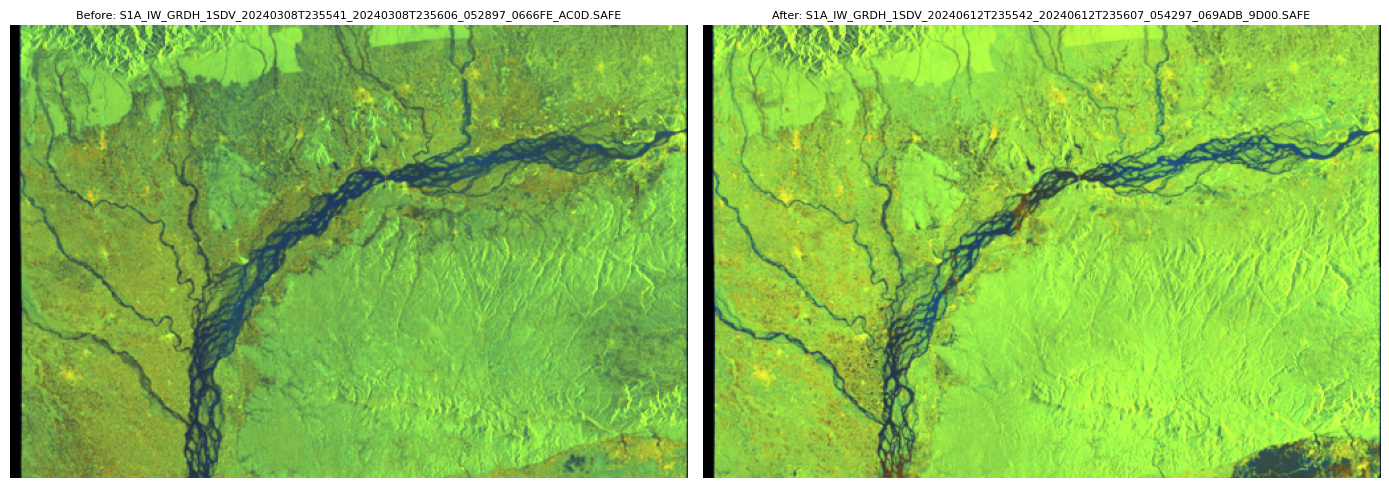

In [ ]:
import glob, os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# reuse your existing variables
dirs = {"Before": before_dir, "After": after_dir}

fig, axes = plt.subplots(1, len(dirs), figsize=(7*len(dirs), 7))

for ax, (label, d) in zip(axes, dirs.items()):
    safe_dirs = glob.glob(os.path.join(d, "*.SAFE"))
    if not safe_dirs:
        ax.text(0.5, 0.5, f"no .SAFE folder found in {d}", ha="center")
        ax.axis("off")
        continue

    safe_dir = safe_dirs[0]
    quicklook = glob.glob(os.path.join(safe_dir, "preview", "quick-look.png"))
    name = os.path.basename(safe_dir)

    if quicklook:
        img = Image.open(quicklook[0])
        ax.imshow(np.fliplr(np.array(img)))
        ax.set_title(f"{label}: {name}", fontsize=8)
    else:
        ax.text(0.5, 0.5, "no quicklook found", ha="center")
    ax.axis("off")

plt.tight_layout()
plt.show()

SOME STATISTICS

In [ ]:
from esa_snappy import ProductIO

before_safe = glob.glob("/content/before/**/*.SAFE", recursive=True)
after_safe  = glob.glob("/content/after/**/*.SAFE", recursive=True)
before = ProductIO.readProduct(before_safe[0])
after  = ProductIO.readProduct(after_safe[0])
print("BEFORE")
print("Name:", before.getName())
print("Product type:", before.getProductType())
print("Width:", before.getSceneRasterWidth())
print("Height:", before.getSceneRasterHeight())
print("Bands:", list(before.getBandNames()))

print("\nAFTER")
print("Name:", after.getName())
print("Product type:", after.getProductType())
print("Width:", after.getSceneRasterWidth())
print("Height:", after.getSceneRasterHeight())
print("Bands:", list(after.getBandNames()))

BEFORE
Name: S1A_IW_GRDH_1SDV_20240308T235541_20240308T235606_052897_0666FE_AC0D
Product type: GRD
Width: 25678
Height: 16736
Bands: ['Amplitude_VH', 'Intensity_VH', 'Amplitude_VV', 'Intensity_VV']

AFTER
Name: S1A_IW_GRDH_1SDV_20240612T235542_20240612T235607_054297_069ADB_9D00
Product type: GRD
Width: 25679
Height: 16736
Bands: ['Amplitude_VH', 'Intensity_VH', 'Amplitude_VV', 'Intensity_VV']


create an output directory

In [ ]:
import os

output_dir = "/content/snap_outputs"
os.makedirs(output_dir, exist_ok=True)

print("Output directory:", output_dir)

Output directory: /content/snap_outputs


Step 1A — Apply Orbit to Before Flood

In [ ]:
from esa_snappy import GPF, HashMap

orbit_params_before = HashMap()

before_orbit = GPF.createProduct(
    "Apply-Orbit-File",
    orbit_params_before,
    before
)

print("Before orbit processing completed.")
print("Product:", before_orbit)

Before orbit processing completed.
Product: org.esa.snap.core.datamodel.Product[name=S1A_IW_GRDH_1SDV_20240308T235541_20240308T235606_052897_0666FE_AC0D_Orb]


Step 1B — Apply Orbit to After Flood

In [ ]:
orbit_params_after = HashMap()

after_orbit = GPF.createProduct(
    "Apply-Orbit-File",
    orbit_params_after,
    after
)

print("After orbit processing completed.")
print("Product:", after_orbit)

After orbit processing completed.
Product: org.esa.snap.core.datamodel.Product[name=S1A_IW_GRDH_1SDV_20240612T235542_20240612T235607_054297_069ADB_9D00_Orb]


Step 1C - Save

In [ ]:
import os
from esa_snappy import ProductIO

output_dir = "/content/snap_outputs"
os.makedirs(output_dir, exist_ok=True)

before_orbit_path = os.path.join(output_dir, "before_orbit.dim")
after_orbit_path  = os.path.join(output_dir, "after_orbit.dim")

ProductIO.writeProduct(before_orbit, before_orbit_path, "BEAM-DIMAP")
ProductIO.writeProduct(after_orbit, after_orbit_path, "BEAM-DIMAP")

print("Before orbit saved:", before_orbit_path)
print("After orbit saved :", after_orbit_path)

Before orbit saved: /content/snap_outputs/before_orbit.dim
After orbit saved : /content/snap_outputs/after_orbit.dim


Step 1D - Visualise

['Amplitude_VH.hdr', 'Amplitude_VH.img', 'Amplitude_VV.hdr', 'Amplitude_VV.img', 'tie_point_grids', 'vector_data']


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


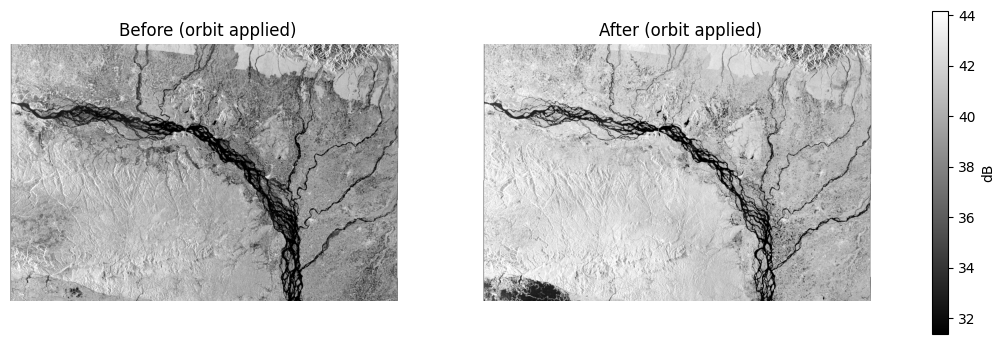

In [ ]:
import os, glob
import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"

# BEAM-DIMAP stores each band as an ENVI .img file inside the .data folder
print(sorted(os.listdir(f"{output_dir}/before_orbit.data")))

def load_preview(dim_name, band="Amplitude_VH", scale=20):
    """Read a heavily downsampled version of one band and convert to dB."""
    img = f"{output_dir}/{dim_name}.data/{band}.img"
    with rasterio.open(img) as src:
        h, w = src.height // scale, src.width // scale
        arr = src.read(1, out_shape=(h, w), resampling=Resampling.average).astype("float32")
    arr[arr <= 0] = np.nan
    return 20 * np.log10(arr)          # amplitude -> dB (use 10*log10 for intensity)

before_db = load_preview("before_orbit")
after_db  = load_preview("after_orbit")

# Stretch contrast using percentiles so the image isn't washed out
vmin, vmax = np.nanpercentile(np.concatenate([before_db.ravel(), after_db.ravel()]), [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, title in zip(ax, [before_db, after_db], ["Before (orbit applied)", "After (orbit applied)"]):
    im = a.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    a.set_title(title); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.6, label="dB")
plt.show()

Step-2 Calibration

In [ ]:
from esa_snappy import GPF, HashMap

cal_params_before = HashMap()

cal_params_before.put("outputSigmaBand", False)
cal_params_before.put("outputBetaBand", False)
cal_params_before.put("outputGammaBand", True)

cal_params_before.put("selectedPolarisations", "VH")

before_gamma0 = GPF.createProduct(
    "Calibration",
    cal_params_before,
    before_orbit
)

print("Before Gamma0 calibration completed.")
print("Product:", before_gamma0)

Before Gamma0 calibration completed.
Product: org.esa.snap.core.datamodel.Product[name=before_orbit_Cal]


In [ ]:
cal_params_after = HashMap()

cal_params_after.put("outputSigmaBand", False)
cal_params_after.put("outputBetaBand", False)
cal_params_after.put("outputGammaBand", True)

cal_params_after.put("selectedPolarisations", "VH")

after_gamma0 = GPF.createProduct(
    "Calibration",
    cal_params_after,
    after_orbit
)

print("After Gamma0 calibration completed.")
print("Product:", after_gamma0)

After Gamma0 calibration completed.
Product: org.esa.snap.core.datamodel.Product[name=after_orbit_Cal]


In [ ]:
before_gamma0_path = os.path.join(
    output_dir,
    "before_gamma0.dim"
)

after_gamma0_path = os.path.join(
    output_dir,
    "after_gamma0.dim"
)

ProductIO.writeProduct(
    before_gamma0,
    before_gamma0_path,
    "BEAM-DIMAP"
)

ProductIO.writeProduct(
    after_gamma0,
    after_gamma0_path,
    "BEAM-DIMAP"
)

print("Before Gamma0 saved:", before_gamma0_path)
print("After Gamma0 saved:", after_gamma0_path)

Before Gamma0 saved: /content/snap_outputs/before_gamma0.dim
After Gamma0 saved: /content/snap_outputs/after_gamma0.dim


Step 2b: Speckle filtering (Refined Lee) on linear Gamma0

In [ ]:
import os
from esa_snappy import ProductIO, GPF, HashMap

output_dir = "/content/snap_outputs"
before_gamma0 = ProductIO.readProduct(os.path.join(output_dir, "before_gamma0.dim"))
after_gamma0  = ProductIO.readProduct(os.path.join(output_dir, "after_gamma0.dim"))

def despeckle(product):
    p = HashMap()
    p.put("sourceBands", "Gamma0_VH")
    p.put("filter", "Refined Lee")
    return GPF.createProduct("Speckle-Filter", p, product)

before_spk = despeckle(before_gamma0)
after_spk  = despeckle(after_gamma0)

ProductIO.writeProduct(before_spk, os.path.join(output_dir, "before_speckle.dim"), "BEAM-DIMAP")
ProductIO.writeProduct(after_spk,  os.path.join(output_dir, "after_speckle.dim"),  "BEAM-DIMAP")

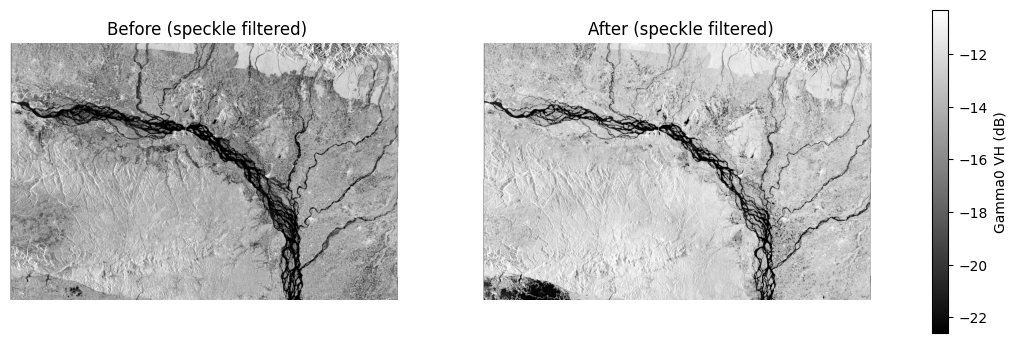

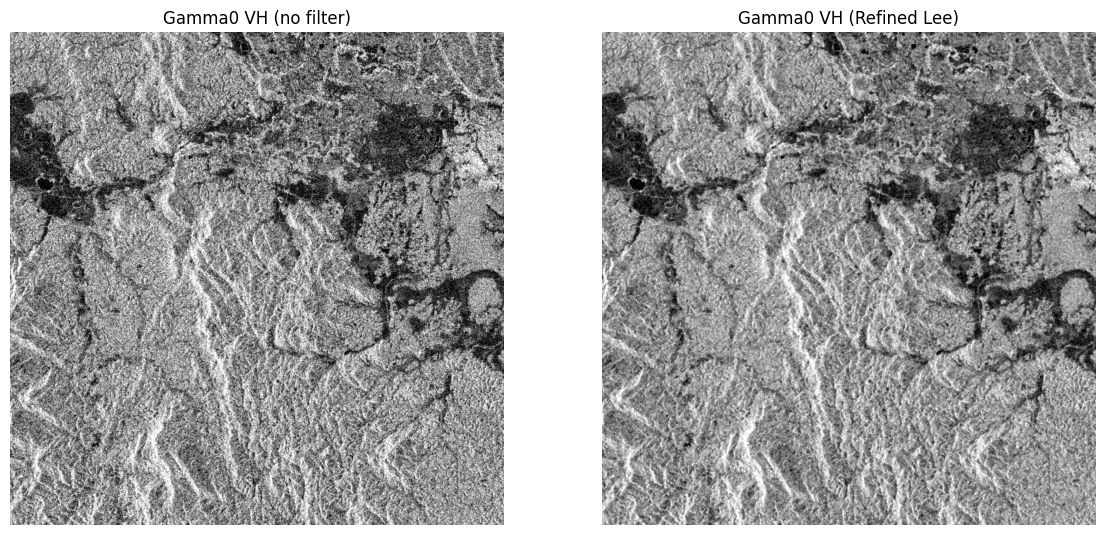

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"

def img_path(dim_name, band="Gamma0_VH"):
    return f"{output_dir}/{dim_name}.data/{band}.img"

def to_db(arr):
    arr = arr.astype("float32")
    arr[arr <= 0] = np.nan
    return 10 * np.log10(arr)          # Gamma0 is linear power -> 10*log10

def read_overview(dim_name, scale=20):
    with rasterio.open(img_path(dim_name)) as src:
        h, w = src.height // scale, src.width // scale
        return to_db(src.read(1, out_shape=(h, w), resampling=Resampling.average))

def read_crop(dim_name, x, y, size=1500):
    with rasterio.open(img_path(dim_name)) as src:
        return to_db(src.read(1, window=Window(x, y, size, size)))

# ---------- 1. Overview: filtered before vs after ----------
b_spk = read_overview("before_speckle")
a_spk = read_overview("after_speckle")
vmin, vmax = np.nanpercentile(np.concatenate([b_spk.ravel(), a_spk.ravel()]), [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [b_spk, a_spk], ["Before (speckle filtered)", "After (speckle filtered)"]):
    im = a.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.6, label="Gamma0 VH (dB)")
plt.show()

# ---------- 2. Zoomed crop: unfiltered vs filtered (same window) ----------
with rasterio.open(img_path("before_speckle")) as src:
    W, H = src.width, src.height
size = 1500
x, y = W // 2 - size // 2, H // 2 - size // 2      # center of the scene; change to look elsewhere

raw  = read_crop("before_gamma0",  x, y, size)
filt = read_crop("before_speckle", x, y, size)
vmin, vmax = np.nanpercentile(raw, [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [raw, filt], ["Gamma0 VH (no filter)", "Gamma0 VH (Refined Lee)"]):
    a.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
plt.show()

Step-3 Terrain Correction

In [ ]:
from esa_snappy import ProductIO
import os
output_dir = "/content/snap_outputs"
before_spk = ProductIO.readProduct(os.path.join(output_dir, "before_speckle.dim"))
after_spk  = ProductIO.readProduct(os.path.join(output_dir, "after_speckle.dim"))

In [ ]:
from esa_snappy import GPF, HashMap

tc_params_before = HashMap()

tc_params_before.put(
    "demName",
    "Copernicus 30m Global DEM" #glo30
)

tc_params_before.put(
    "pixelSpacingInMeter",
    10.0
)

tc_params_before.put(
    "mapProjection",
    "AUTO:42001"
)

tc_params_before.put(
    "sourceBands",
    "Gamma0_VH"
)

before_tc = GPF.createProduct(
    "Terrain-Correction",
    tc_params_before,
    before_spk
)

print("Before terrain correction completed.")
print("Product:", before_tc)

Before terrain correction completed.
Product: org.esa.snap.core.datamodel.Product[name=before_speckle_TC]


In [ ]:
tc_params_after = HashMap()

tc_params_after.put(
    "demName",
    "Copernicus 30m Global DEM"
)

tc_params_after.put(
    "pixelSpacingInMeter",
    10.0
)

tc_params_after.put(
    "mapProjection",
    "AUTO:42001"
)

tc_params_after.put(
    "sourceBands",
    "Gamma0_VH"
)

after_tc = GPF.createProduct(
    "Terrain-Correction",
    tc_params_after,
    after_spk
)

print("After terrain correction completed.")
print("Product:", after_tc)

After terrain correction completed.
Product: org.esa.snap.core.datamodel.Product[name=after_speckle_TC]


In [ ]:
before_tc_path = os.path.join(output_dir, "before_terrain_corrected.dim")
after_tc_path  = os.path.join(output_dir, "after_terrain_corrected.dim")

ProductIO.writeProduct(before_tc, before_tc_path, "BEAM-DIMAP")
ProductIO.writeProduct(after_tc, after_tc_path, "BEAM-DIMAP")

print("Before TC saved:", before_tc_path)
print("After TC saved :", after_tc_path)

Before TC saved: /content/snap_outputs/before_terrain_corrected.dim
After TC saved : /content/snap_outputs/after_terrain_corrected.dim


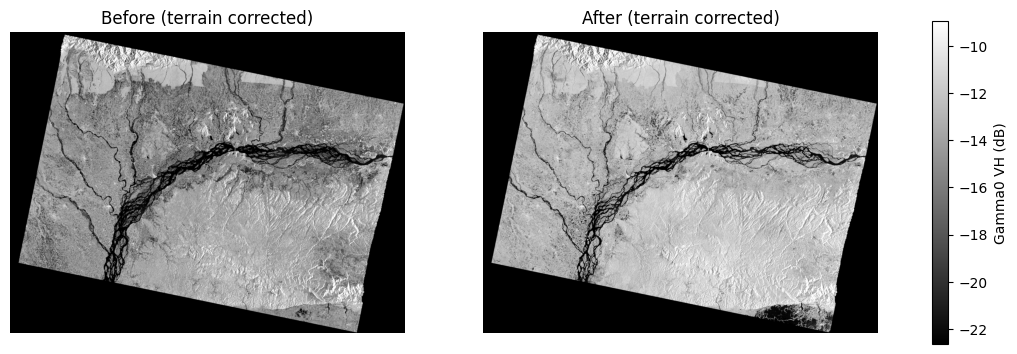

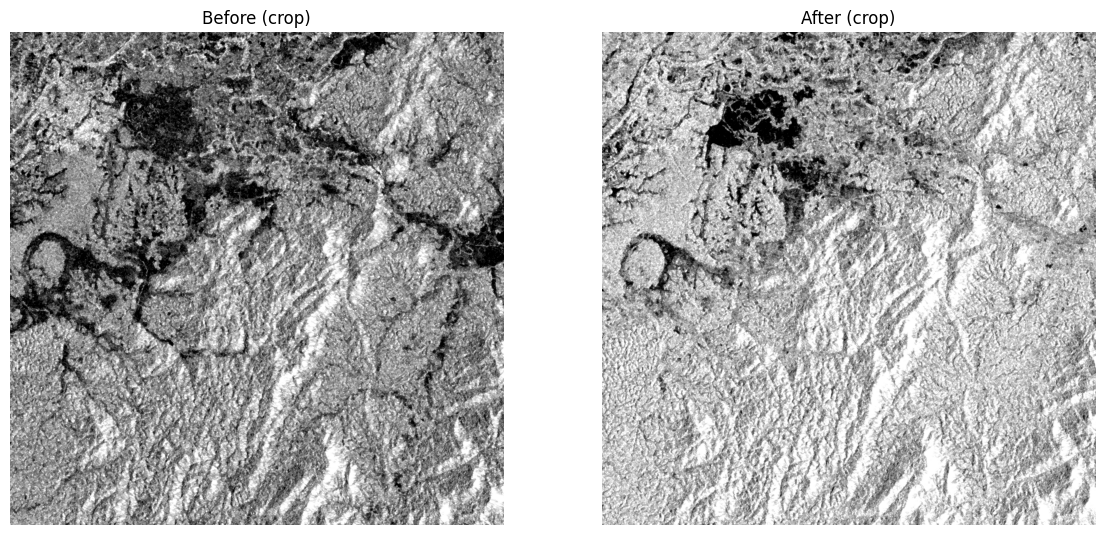

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"

def img_path(dim_name, band="Gamma0_VH"):
    return f"{output_dir}/{dim_name}.data/{band}.img"

def to_db(arr):
    arr = arr.astype("float32")
    arr[arr <= 0] = np.nan             # no-data outside the swath is 0
    return 10 * np.log10(arr)

def read_overview(dim_name, scale=20):
    with rasterio.open(img_path(dim_name)) as src:
        h, w = src.height // scale, src.width // scale
        return to_db(src.read(1, out_shape=(h, w), resampling=Resampling.average))

def read_crop(dim_name, x, y, size=1500):
    with rasterio.open(img_path(dim_name)) as src:
        return to_db(src.read(1, window=Window(x, y, size, size)))

# ---------- 1. Overview: terrain-corrected before vs after ----------
b_tc = read_overview("before_terrain_corrected")
a_tc = read_overview("after_terrain_corrected")
vmin, vmax = np.nanpercentile(np.concatenate([b_tc.ravel(), a_tc.ravel()]), [2, 98])

cmap = plt.get_cmap("gray").copy()
cmap.set_bad("black")                  # no-data area shown in black

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [b_tc, a_tc], ["Before (terrain corrected)", "After (terrain corrected)"]):
    im = a.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.6, label="Gamma0 VH (dB)")
plt.show()

# ---------- 2. Zoomed crop at full 10 m resolution ----------
with rasterio.open(img_path("before_terrain_corrected")) as src:
    W, H = src.width, src.height
size = 1500
x, y = W // 2 - size // 2, H // 2 - size // 2      # change to look elsewhere

b_crop = read_crop("before_terrain_corrected", x, y, size)
a_crop = read_crop("after_terrain_corrected",  x, y, size)
vmin, vmax = np.nanpercentile(b_crop, [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [b_crop, a_crop], ["Before (crop)", "After (crop)"]):
    a.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
plt.show()

Step-4 Collocation

In [ ]:
# ============================================================
# Step 4: Collocation
# ============================================================
from esa_snappy import GPF, HashMap, ProductIO
import numpy as np, os

output_dir = "/content/snap_outputs"
os.makedirs(output_dir, exist_ok=True)

# Reload standalone (non-lazy) versions from disk — safe even if
# before_tc/after_tc were disposed or the runtime was restarted
before_tc = ProductIO.readProduct(os.path.join(output_dir, "before_terrain_corrected.dim"))
after_tc  = ProductIO.readProduct(os.path.join(output_dir, "after_terrain_corrected.dim"))

collocation_params = HashMap()
collocation_params.put("targetProductType", "COLLOCATED")
collocation_params.put("renameReferenceComponents", True)
collocation_params.put("renameSecondaryComponents", True)

collocated = GPF.createProduct("Collocate", collocation_params, [before_tc, after_tc])

print("Collocation bands:", list(collocated.getBandNames()))
# Expect: ['Gamma0_VH_M', 'Gamma0_VH_S', 'collocationFlags']

# Save collocated product
collocated_path = os.path.join(output_dir, "collocated.dim")
ProductIO.writeProduct(collocated, collocated_path, "BEAM-DIMAP")
print("Collocated saved:", collocated_path)

Collocation bands: ['Gamma0_VH_M', 'Gamma0_VH_S', 'collocationFlags']
Collocated saved: /content/snap_outputs/collocated.dim


['Gamma0_VH_M.hdr', 'Gamma0_VH_M.img', 'Gamma0_VH_S.hdr', 'Gamma0_VH_S.img', 'collocationFlags.hdr', 'collocationFlags.img', 'vector_data']


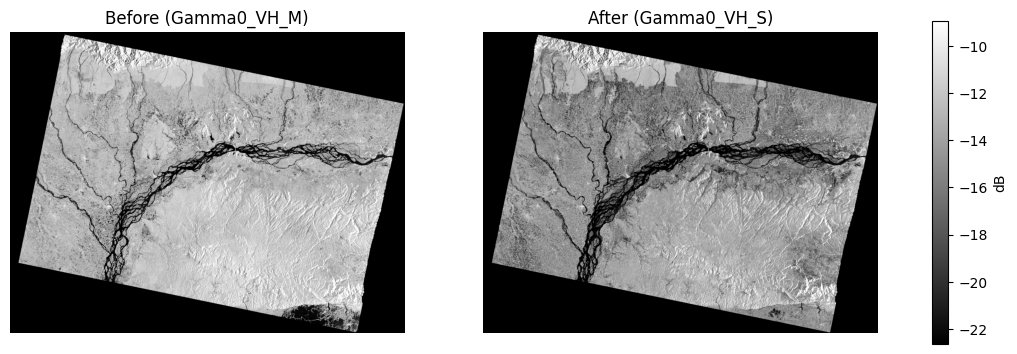

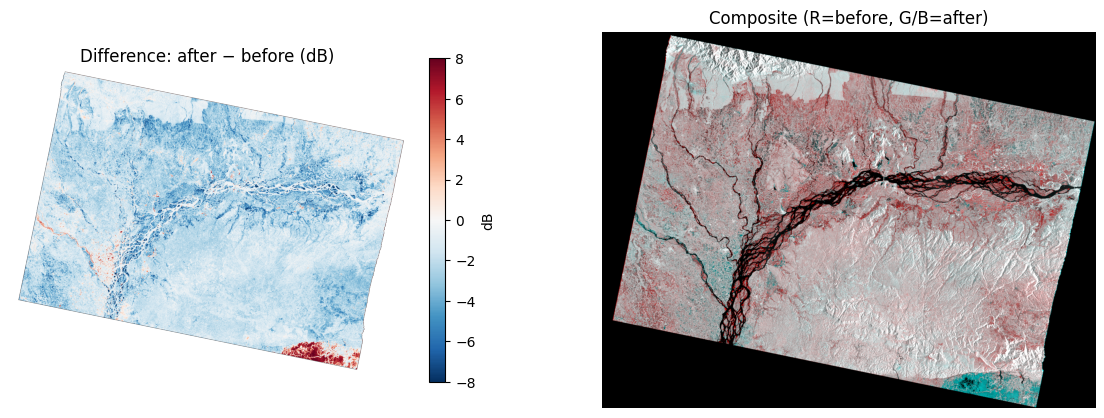

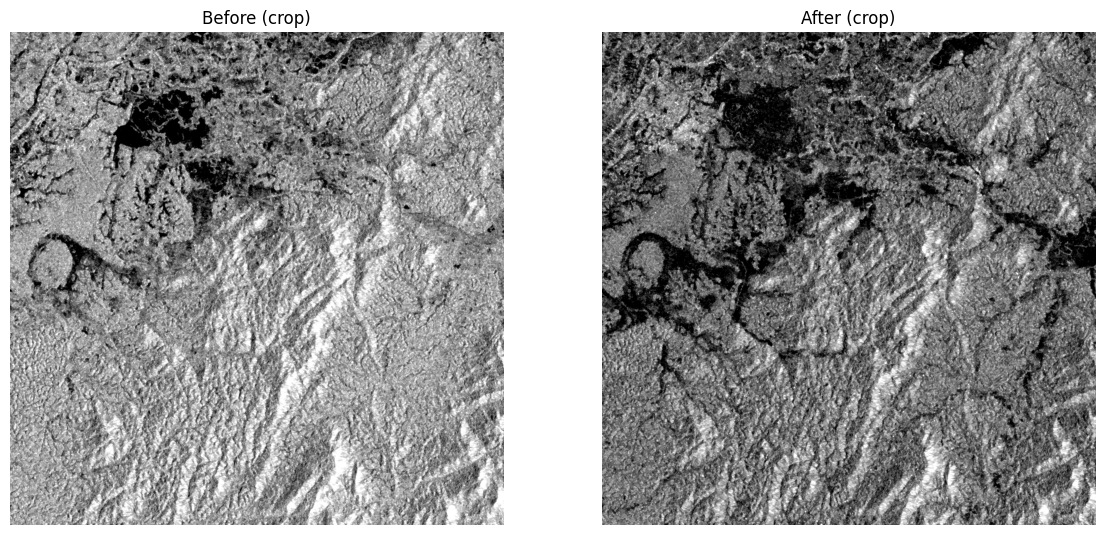

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"
print(sorted(os.listdir(f"{output_dir}/collocated.data")))   # check band files exist

def img_path(band):
    return f"{output_dir}/collocated.data/{band}.img"

def to_db(arr):
    arr = arr.astype("float32")
    arr[arr <= 0] = np.nan
    return 10 * np.log10(arr)

def read_overview(band, scale=20):
    with rasterio.open(img_path(band)) as src:
        h, w = src.height // scale, src.width // scale
        return to_db(src.read(1, out_shape=(h, w), resampling=Resampling.average))

def read_crop(band, x, y, size=1500):
    with rasterio.open(img_path(band)) as src:
        return to_db(src.read(1, window=Window(x, y, size, size)))

def stretch(a, lo=2, hi=98):
    l, h = np.nanpercentile(a, [lo, hi])
    return np.clip((a - l) / (h - l), 0, 1)

cmap = plt.get_cmap("gray").copy(); cmap.set_bad("black")

# ---------- 1. Before vs after on the SAME grid ----------
m = read_overview("Gamma0_VH_M")
s = read_overview("Gamma0_VH_S")
vmin, vmax = np.nanpercentile(np.concatenate([m.ravel(), s.ravel()]), [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [m, s], ["Before (Gamma0_VH_M)", "After (Gamma0_VH_S)"]):
    im = a.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.6, label="dB")
plt.show()

# ---------- 2. Difference (after - before) and RGB change composite ----------
diff = s - m                                   # negative = got darker = possible flooding
rgb = np.dstack([stretch(m), stretch(s), stretch(s)])   # R=before, G=after, B=after
rgb[np.isnan(rgb)] = 0

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
im = ax[0].imshow(diff, cmap="RdBu_r", vmin=-8, vmax=8)
ax[0].set_title("Difference: after − before (dB)"); ax[0].axis("off")
fig.colorbar(im, ax=ax[0], shrink=0.6, label="dB")
ax[1].imshow(rgb)
ax[1].set_title("Composite (R=before, G/B=after)"); ax[1].axis("off")
plt.show()

# ---------- 3. Full-resolution crop ----------
with rasterio.open(img_path("Gamma0_VH_M")) as src:
    W, H = src.width, src.height
size = 1500
x, y = W // 2 - size // 2, H // 2 - size // 2      # move toward the river to see flooding

mc, sc = read_crop("Gamma0_VH_M", x, y, size), read_crop("Gamma0_VH_S", x, y, size)
vmin, vmax = np.nanpercentile(mc, [2, 98])
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [mc, sc], ["Before (crop)", "After (crop)"]):
    a.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
plt.show()

Step 5: Convert Gamma0 linear -> dB

In [ ]:
from esa_snappy import GPF, HashMap, ProductIO
db_params = HashMap()
db_params.put("sourceBands", "Gamma0_VH_M,Gamma0_VH_S")

collocated_db = GPF.createProduct("LinearToFromdB", db_params, collocated)

db_band_names = list(collocated_db.getBandNames())
print("dB-converted bands:", db_band_names)
# SNAP appends a "_db" suffix, e.g. ['Gamma0_VH_M_db', 'Gamma0_VH_S_db', 'collocationFlags']

# Save collocated_db product
collocated_db_path = os.path.join(output_dir, "collocated_db.dim")
ProductIO.writeProduct(collocated_db, collocated_db_path, "BEAM-DIMAP")
print("Collocated dB saved:", collocated_db_path)

dB-converted bands: ['Gamma0_VH_M_db', 'Gamma0_VH_S_db', 'collocationFlags']
Collocated dB saved: /content/snap_outputs/collocated_db.dim


In [ ]:
# ============================================================
# Step 5b: Export before / after dB images as GeoTIFF (model input)
# ============================================================
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.transform import from_bounds
from rasterio.warp import transform as warp_transform
from esa_snappy import ProductIO, PixelPos

output_dir  = "/content/snap_outputs"
tile_height = 2000

# Reload from disk so this cell works standalone (even after a restart)
collocated_db = ProductIO.readProduct(os.path.join(output_dir, "collocated_db.dim"))
band_names  = list(collocated_db.getBandNames())
before_name = [b for b in band_names if "_M_db" in b][0]   # Gamma0_VH_M_db = BEFORE
after_name  = [b for b in band_names if "_S_db" in b][0]   # Gamma0_VH_S_db = AFTER
print("Before band:", before_name, "| After band:", after_name)

width  = collocated_db.getSceneRasterWidth()
height = collocated_db.getSceneRasterHeight()

# Georeferencing (same approach as Step 7, so the TIFFs are valid GeoTIFFs)
gc = collocated_db.getSceneGeoCoding()
crs_wkt = gc.getMapCRS().toWKT()
ul = gc.getGeoPos(PixelPos(0, 0), None)
lr = gc.getGeoPos(PixelPos(width, height), None)
xs, ys = warp_transform("EPSG:4326", crs_wkt, [ul.lon, lr.lon], [ul.lat, lr.lat])
transform = from_bounds(xs[0], ys[1], xs[1], ys[0], width, height)
print("Size:", width, "x", height, "| Pixel size (m):", transform.a)

def export_band(band_name, out_name):
    band = collocated_db.getBand(band_name)
    out_path = os.path.join(output_dir, out_name)

    with rasterio.open(
        out_path, "w",
        driver="GTiff", height=height, width=width, count=1,
        dtype="float32", crs=crs_wkt, transform=transform,
        nodata=np.nan,
        compress="lzw", predictor=3,
        tiled=True, blockxsize=256, blockysize=256,
        BIGTIFF="IF_SAFER",
    ) as dst:
        for y in range(0, height, tile_height):
            h = min(tile_height, height - y)
            tile = np.zeros(width * h, dtype=np.float32)
            band.readPixels(0, y, width, h, tile)
            tile[~np.isfinite(tile)] = np.nan      # -inf (log10 of 0) / NaN -> nodata
            dst.write(tile.reshape(h, width), 1, window=Window(0, y, width, h))
            del tile

    print("Saved:", out_path, f"({os.path.getsize(out_path)/1e9:.2f} GB)")
    return out_path

before_tif = export_band(before_name, "before_db.tif")
after_tif  = export_band(after_name,  "after_db.tif")

# Quick check: both files must be on the identical grid
with rasterio.open(before_tif) as b, rasterio.open(after_tif) as a:
    assert b.shape == a.shape and b.transform == a.transform and b.crs == a.crs
    print("Shape:", b.shape, "| CRS:", b.crs, "| dtype:", b.dtypes[0], "| nodata:", b.nodata)

Before band: Gamma0_VH_M_db | After band: Gamma0_VH_S_db
Size: 28789 x 21941 | Pixel size (m): 10.000000000204222
Saved: /content/snap_outputs/before_db.tif (1.70 GB)
Saved: /content/snap_outputs/after_db.tif (1.67 GB)
Shape: (21941, 28789) | CRS: EPSG:32646 | dtype: float32 | nodata: nan


In [ ]:
import shutil
import os

output_dir = "/content/snap_outputs"
drive_dest = "/content/drive/MyDrive/snap_outputs_aaaj"  # change folder name if you want

os.makedirs(drive_dest, exist_ok=True)

files_to_copy = [
    "before_db.tif",
    "after_db.tif",
]

for fname in files_to_copy:
    src = os.path.join(output_dir, fname)
    dst = os.path.join(drive_dest, fname)
    if os.path.exists(src):
        shutil.copy(src, dst)
        print(f"Copied: {fname} ({os.path.getsize(src) / 1e9:.2f} GB)")
    else:
        print(f"Missing, skipped: {fname}")

print("\nDone. Files are in your Drive under 'snap_outputs'.")

Copied: before_db.tif (1.70 GB)
Copied: after_db.tif (1.67 GB)

Done. Files are in your Drive under 'snap_outputs'.
